Decision Tree
Studen: Sima Arian

In [31]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
# Import machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer

In [33]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


In [34]:
# Import Decision Tree visualization
from sklearn.tree import plot_tree

Part 1

In [35]:
# 1. Load the Dataset
df = pd.read_csv('loans_dataset.csv')

Part2 - Data exploration

In [36]:
# 2. Explore the Dataset
print("Dataset Head:")
print(df.head()) 

Dataset Head:
   initial_payment  last_payment  credit_score  house_number    sum result
0              201         10018           250          3046  13515    yes
1              205         10016           395          3044  13660    yes
2              257         10129           109          3251  13746    yes
3              246         10064           324          3137  13771    yes
4              117         10115           496          3094  13822    yes


In [37]:
#Display the last 5 rows
print("last 5 row of data")
df.tail()

last 5 row of data


,initial_payment,last_payment,credit_score,house_number,sum,result
999,168,14798,834,4937,20737,No
1000,234,14567,756,4766,20678,yes
1001,450,13897,867,7896,210456,yes
1002,347,14999,687,9876,246789,yes
1003,467,13555,666,7899,21786,yes


In [38]:
#Check the shape of the dataset
print("Dataset Shape:", df.shape)

Dataset Shape: (1004, 6)


In [39]:
print("\nDataset Info:")
print(df.info())


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004 entries, 0 to 1003
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   initial_payment  1004 non-null   int64 
 1   last_payment     1004 non-null   int64 
 2   credit_score     1004 non-null   int64 
 3   house_number     1004 non-null   int64 
 4   sum              1004 non-null   int64 
 5   result           1004 non-null   object
dtypes: int64(5), object(1)
memory usage: 47.2+ KB
None


In [40]:
print("\nSummary Statistics:")
print(df.describe())


Summary Statistics:
       initial_payment  last_payment  credit_score  house_number  \
count      1004.000000   1004.000000   1004.000000   1004.000000   
mean        294.662351  12473.009960    528.902390   4041.282869   
std         115.844218   1442.134231    259.681745    618.431417   
min         100.000000  10005.000000    100.000000   3003.000000   
25%         195.750000  11213.500000    302.750000   3546.500000   
50%         290.000000  12467.000000    518.000000   4046.000000   
75%         398.000000  13690.000000    755.000000   4508.750000   
max         500.000000  14999.000000    997.000000   9876.000000   

                 sum  
count    1004.000000  
mean    17744.012948  
std      9594.659715  
min     13515.000000  
25%     16081.250000  
50%     17383.000000  
75%     18608.250000  
max    246789.000000  


In [41]:
#Check column names
print(df.columns)

Index(['initial_payment', 'last_payment', 'credit_score', 'house_number',
       'sum', 'result'],
      dtype='object')


Part 3 – Data Preprocessing

In [42]:
#Remove duplicate rows
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (1004, 6)


In [43]:
#Identify the features and target variable
# Features
X = df.drop('result', axis=1)

# Target variable
y = df['result']

print("Features:")
print(X.head())

print("Target:")
print(y.head())

Features:
   initial_payment  last_payment  credit_score  house_number    sum
0              201         10018           250          3046  13515
1              205         10016           395          3044  13660
2              257         10129           109          3251  13746
3              246         10064           324          3137  13771
4              117         10115           496          3094  13822
Target:
0    yes
1    yes
2    yes
3    yes
4    yes
Name: result, dtype: object


In [44]:
#Check numerical data
print(X.dtypes)

initial_payment    int64
last_payment       int64
credit_score       int64
house_number       int64
sum                int64
dtype: object


In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (803, 5)
X_test shape: (201, 5)


In [46]:
#Handle missing values
imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)
print("Missing values handled successfully!")

Missing values handled successfully!


In [47]:
#Normalize the features


scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Training and testing data are ready!")

Training and testing data are ready!


Part 4 - Modeling

In [48]:
# Create the Decision Tree Classifier

model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

# Train the model

model.fit(X_train_scaled, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [49]:
# Make predictions

y_pred = model.predict(X_test_scaled)

# Display actual and predicted values

results = pd.DataFrame({
    'Actual Result': y_test.values,
    'Predicted Result': y_pred
})

results.head(10)

,Actual Result,Predicted Result
0,yes,yes
1,No,No
2,yes,yes
3,yes,yes
4,yes,yes
5,yes,yes
6,No,No
7,yes,yes
8,yes,yes
9,yes,yes


Part 5 – Evaluate the Model

In [50]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

print("Model Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 1.0
Model Accuracy Percentage: 100.0 %


In [51]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[104   0]
 [  0  97]]


In [60]:
print("Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00       104
         yes       1.00      1.00      1.00        97

    accuracy                           1.00       201
   macro avg       1.00      1.00      1.00       201
weighted avg       1.00      1.00      1.00       201



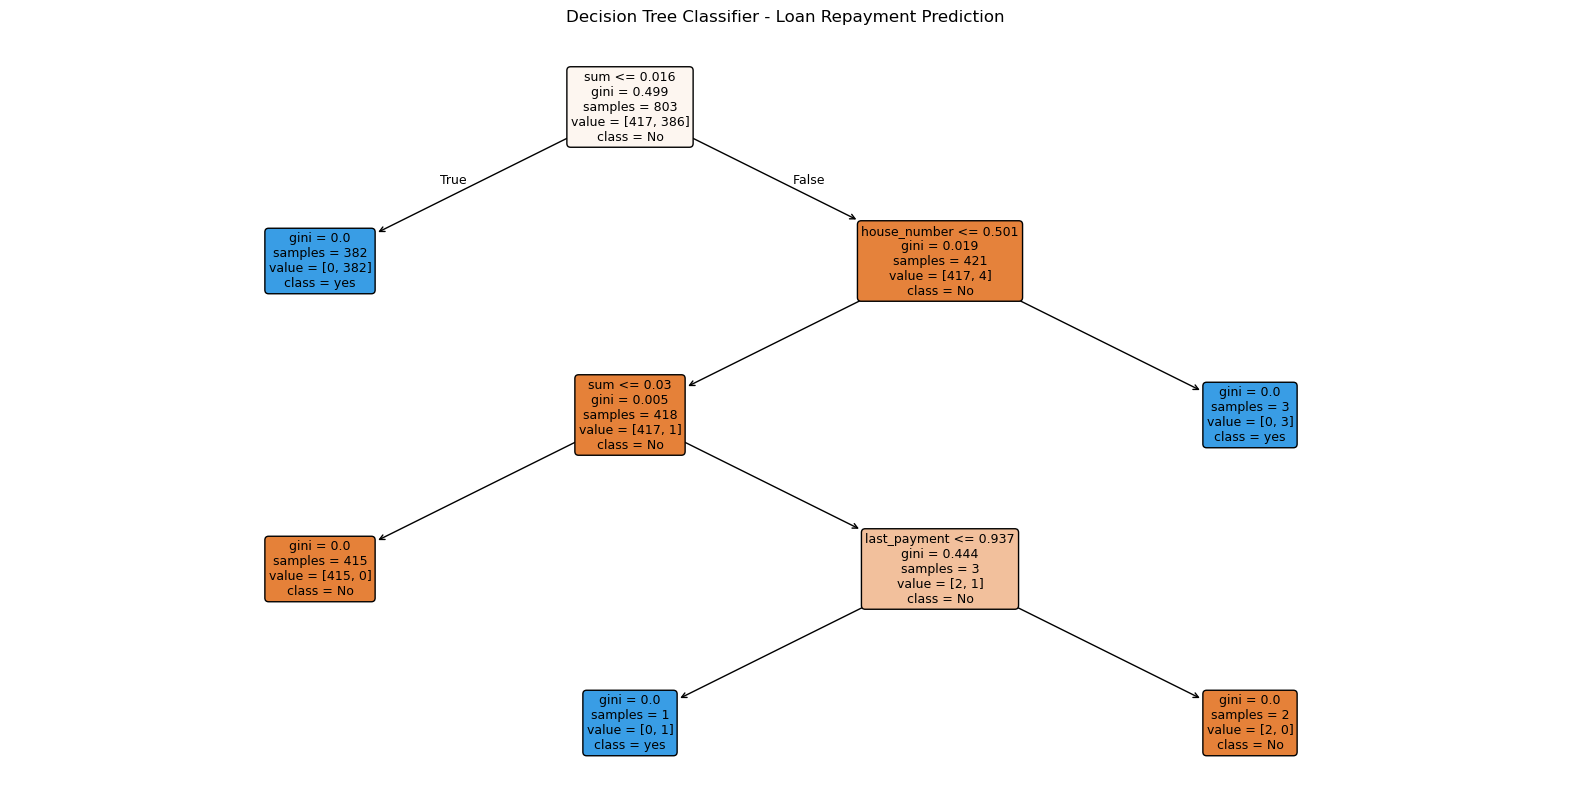

In [53]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Classifier - Loan Repayment Prediction")

plt.show()